# Parte 4 · La escala también es geometría (4.1 a 4.4)

**Autor:** Gregorio Coronel · Grupo Taiwan

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

Esta es la única parte que usa también las variables **crudas**: `cargar_taiwan(..., escalar=False)` da la misma partición 80/20 sin estandarizar. Las desviaciones estándar son las que guardó 0.4 en `resultados/sd_taiwan.csv` y las consultas son las de 2.1 en `resultados/consultas.json`.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from datos import cargar_taiwan

X_train, X_test, y_train, y_test, _ = cargar_taiwan("../data/taiwan_credit.csv")
Xc_train, Xc_test, _, _, _ = cargar_taiwan("../data/taiwan_credit.csv", escalar=False)
sd = pd.read_csv("../resultados/sd_taiwan.csv", index_col=0)["sd"]
hp = json.load(open("../resultados/hiperparametros.json"))
consultas = json.load(open("../resultados/consultas.json"))
mse = lambda y, p: np.mean((y - p) ** 2)
assert (Xc_train.index == X_train.index).all() and np.allclose(Xc_train.std(ddof=0), sd)

## 4.1 · k-NN con $k = 10$ en tres escalas

Se ajusta el mismo `KNeighborsRegressor(n_neighbors=10)` sobre las variables crudas, las estandarizadas y los componentes principales que explican el 90 % de la varianza. El PCA se ajusta con el entrenamiento estandarizado; como referencia se agrega también el PCA sobre las crudas y el MSE de predecir siempre la tasa de mora del entrenamiento.

In [2]:
pca = PCA(n_components=0.90).fit(X_train)
pca_crudo = PCA(n_components=0.90).fit(Xc_train)
espacios = {
    "crudas": (Xc_train, Xc_test),
    "estandarizadas": (X_train, X_test),
    f"PCA 90 % de las estandarizadas ({pca.n_components_} comp.)": (pca.transform(X_train), pca.transform(X_test)),
    f"PCA 90 % de las crudas ({pca_crudo.n_components_} comp.)": (pca_crudo.transform(Xc_train), pca_crudo.transform(Xc_test)),
}
knn = {nombre: KNeighborsRegressor(n_neighbors=10).fit(a, y_train) for nombre, (a, _) in espacios.items()}
error_knn = pd.Series({nombre: mse(y_test, knn[nombre].predict(b)) for nombre, (_, b) in espacios.items()})
error_knn["(predecir la media)"] = mse(y_test, y_train.mean())
error_knn.to_frame("MSE de prueba").round(4)

,MSE de prueba
crudas,0.1706
estandarizadas,0.1471
PCA 90 % de las estandarizadas (13 comp.),0.1508
PCA 90 % de las crudas (2 comp.),0.1746
(predecir la media),0.1695


In [3]:
# En escala cruda, E||x_i − x_j||² = 2 Σ_v sd_v²: cada variable pesa en la distancia según su varianza
peso = (sd**2 / (sd**2).sum()).sort_values(ascending=False)
grupo = lambda v: "montos" if v.startswith(("LIMIT", "BILL", "PAY_AMT")) else "otras"
print("Parte de la distancia cruda que aportan los montos:", f"{peso.groupby(grupo).sum()['montos']:.6f}")
pd.DataFrame({"sd": sd[peso.index], "parte de la distancia cruda": peso,
              "parte en estandarizadas": 1 / len(sd)}).head(8).style.format({"sd": "{:,.1f}", "parte de la distancia cruda": "{:.4f}", "parte en estandarizadas": "{:.4f}"})

Parte de la distancia cruda que aportan los montos: 1.000000


,sd,parte de la distancia cruda,parte en estandarizadas
LIMIT_BAL,"129,479.7",0.3704,0.0435
BILL_AMT1,"73,525.2",0.1194,0.0435
BILL_AMT2,"70,960.6",0.1112,0.0435
BILL_AMT3,"69,505.3",0.1067,0.0435
BILL_AMT4,"64,153.3",0.0909,0.0435
BILL_AMT5,"60,673.6",0.0813,0.0435
BILL_AMT6,"59,424.7",0.0780,0.0435
PAY_AMT2,"23,436.6",0.0121,0.0435


In [4]:
print(f"Parte de la distancia cruda de PAY_0 a PAY_6: {peso.filter(like='PAY_').drop(peso.filter(like='PAY_AMT').index).sum():.2e}")
print(f"Primer componente del PCA crudo: varianza explicada {pca_crudo.explained_variance_ratio_[0]:.3f}")
pd.Series(pca_crudo.components_[0], index=X_train.columns).abs().sort_values(ascending=False).head(5).round(3)

Parte de la distancia cruda de PAY_0 a PAY_6: 1.79e-10
Primer componente del PCA crudo: varianza explicada 0.610


LIMIT_BAL    0.490
BILL_AMT1    0.389
BILL_AMT2    0.381
BILL_AMT3    0.374
BILL_AMT4    0.346
dtype: float64

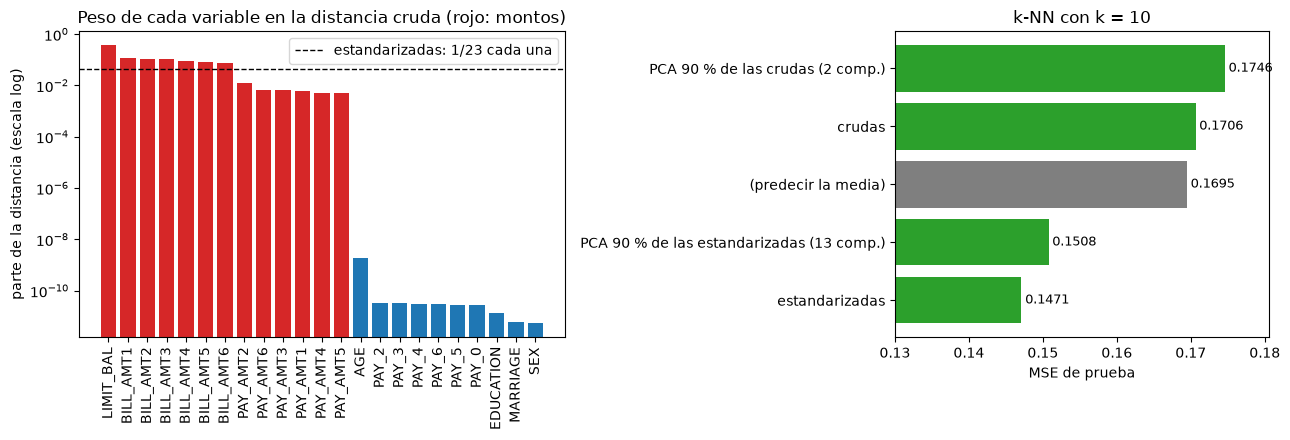

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
colores = ["tab:red" if grupo(v) == "montos" else "tab:blue" for v in peso.index]
ejes[0].bar(peso.index, peso, color=colores)
ejes[0].set_yscale("log")
ejes[0].axhline(1 / len(sd), color="k", ls="--", lw=1, label="estandarizadas: 1/23 cada una")
ejes[0].tick_params(axis="x", rotation=90)
ejes[0].set(ylabel="parte de la distancia (escala log)", title="Peso de cada variable en la distancia cruda (rojo: montos)")
ejes[0].legend()
e = error_knn.sort_values()
ejes[1].barh(e.index, e, color=["tab:gray" if "media" in i else "tab:green" for i in e.index])
ejes[1].set_xlim(0.13, e.max() + 0.006)
ejes[1].set(xlabel="MSE de prueba", title="k-NN con k = 10")
for i, v in enumerate(e):
    ejes[1].text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../figs/parte4_knn_escala.png", dpi=150)
plt.show()

> **Pregunta 4.1.** Reporten el error de prueba. Con las desviaciones estándar de 0.4, ¿qué variables dominan la distancia en escala cruda? ¿Estandarizar siempre ayuda?

**Error de prueba de k-NN con $k = 10$:** 0.1706 con las variables crudas, 0.1471 estandarizadas y 0.1508 con los 13 componentes principales que explican el 90 % de la varianza de las estandarizadas. En escala cruda, k-NN es **peor que predecir siempre la tasa de mora** (0.1695).

**Qué domina la distancia cruda.** La distancia euclidiana al cuadrado es la suma de $(x_{iv} - x_{jv})^2$ sobre las variables, y en promedio cada variable aporta $2\,\text{sd}_v^2$. Entonces el peso de cada variable es proporcional a su varianza. `LIMIT_BAL` (sd ≈ 129 000) se lleva el 37 % de la distancia, los seis `BILL_AMT` cerca del 59 % y los `PAY_AMT` el resto: los montos se llevan prácticamente el 100 %. Los meses de atraso `PAY_0`–`PAY_6`, que son las variables que más predicen la mora (Parte 2), aportan juntos $2 \times 10^{-10}$ de la distancia: en crudo k-NN no los ve. Busca clientes con límite y facturas parecidas, aunque uno vaya al día y el otro lleve meses sin pagar. El PCA de las crudas lo confirma: 2 componentes ya explican el 90 % de la varianza (el primero, 61 %, es casi solo `LIMIT_BAL` y `BILL_AMT`), y k-NN sobre ellos es el peor de todos (0.1746).

**¿Estandarizar siempre ayuda?** No. Aquí ayuda porque la variable informativa (`PAY_0`) tenía una desviación estándar diminuta. Pero estandarizar no le da a cada variable el peso que merece para predecir, sino **el mismo peso a todas**: `SEX` o `MARRIAGE` cuentan lo mismo que `PAY_0`, y los seis `BILL_AMT`, que se mueven juntos, votan seis veces. Si las variables con desviación grande fueran las que predicen y las chicas fueran ruido, estandarizar empeoraría a k-NN. Lo mismo pasa con el PCA: quedarse con el 90 % de la varianza (0.1508) es peor que usar todas las estandarizadas (0.1471), porque el 10 % que se tira tenía información sobre $y$. Varianza no es lo mismo que relevancia. Escoger la escala es escoger el kernel, y ninguna escala automática garantiza el bueno.